<a href="https://colab.research.google.com/github/houmanhaghi/Gold3n-mind/blob/AI-Estimator/gold3n_mind.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pursose**


combination of
  * Buying Au Formula
  * AI Estimation Market

## Buying Au Formula

## AI Estimation Market

In [1]:
! pip install persiantools

In [2]:
import requests
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from persiantools.jdatetime import JalaliDate

In [ ]:
csv_name = str()

### Data Mining

In [10]:
# today = JalaliDate.today().strftime("%Y-%m-%d")

# url = f"https://api.navasan.tech/ohlcSearch/?api_key=freerPVwKRSCRE1qK2YztQ03toKrnDte&item=18ayar&start=1397-01-01&end={today}"

# response = requests.get(url)
# data = response.json()

In [11]:
original_data = data.copy()

In [12]:
df = pd.DataFrame(data)
df = df.drop(columns=['timestamp'])
df = df.drop_duplicates(subset='date', keep='first')
df = df.reset_index(drop=True)
df = df.sort_values(by='date')

In [13]:
df['gregorian_date'] = df['date'].apply(lambda x: JalaliDate(int(x[:4]), int(x[5:7]), int(x[8:10])).to_gregorian())
df['gregorian_date'] = pd.to_datetime(df['gregorian_date'])

In [16]:
df.head()

,date,open,high,low,close,gregorian_date
0,1398-03-19,406297,410000,406297,410000,2019-06-09
1,1398-03-20,410000,415300,407900,415300,2019-06-10
2,1398-03-21,415300,415300,410900,411600,2019-06-11
3,1398-03-22,411600,414600,411143,414600,2019-06-12
4,1398-03-23,414600,428900,414600,428900,2019-06-13


In [14]:
df.tail()

,date,open,high,low,close,gregorian_date
1973,1403-09-09,4561610,4561610,4561610,4561610,2024-11-29
1974,1403-09-10,4561610,4648410,4561610,4577080,2024-11-30
1975,1403-09-11,4577080,4603860,4544300,4564380,2024-12-01
1976,1403-09-12,4564380,4594630,4560460,4587470,2024-12-02
1977,1403-09-13,4587470,4587470,4587470,4587470,2024-12-03


In [20]:
csv_name = f"gold-grm18ayar-iran?start={df[df.index==0]['date'].values[0]}&end={df[df.index==max(df.index)]['date'].values[0]}.csv"
df.to_csv(csv_name, index=False)

In [18]:
original_df = df.copy()

### R&D Estimation

In [21]:
df = pd.read_csv(csv_name)

In [33]:
train_data = df[df['date'] < '1402-02-15'][['gregorian_date','close']]
test_data  = df[df['date'] >='1402-02-15'][['gregorian_date','close']]

In [ ]:
train_data['gregorian_date'] = pd.to_datetime(train_data['gregorian_date'], errors='coerce')
test_data['gregorian_date'] = pd.to_datetime(test_data['gregorian_date'], errors='coerce')

train_data = train_data.dropna(subset=['gregorian_date'])
test_data = test_data.dropna(subset=['gregorian_date'])

train_data['close'] = pd.to_numeric(train_data['close'], errors='coerce')
test_data['close'] = pd.to_numeric(test_data['close'], errors='coerce')

train_data = train_data.dropna(subset=['close'])
test_data = test_data.dropna(subset=['close'])

In [ ]:
train_data.tail()

,gregorian_date,close
1411,2023-04-30,2745050
1412,2023-05-01,2747130
1413,2023-05-02,2721960
1414,2023-05-03,2725660
1415,2023-05-04,2734890


In [ ]:
test_data.tail()

,gregorian_date,close
1967,2024-11-23,4663880
1968,2024-11-24,4563230
1969,2024-11-25,4473430
1970,2024-11-26,4464430
1971,2024-11-27,4508060


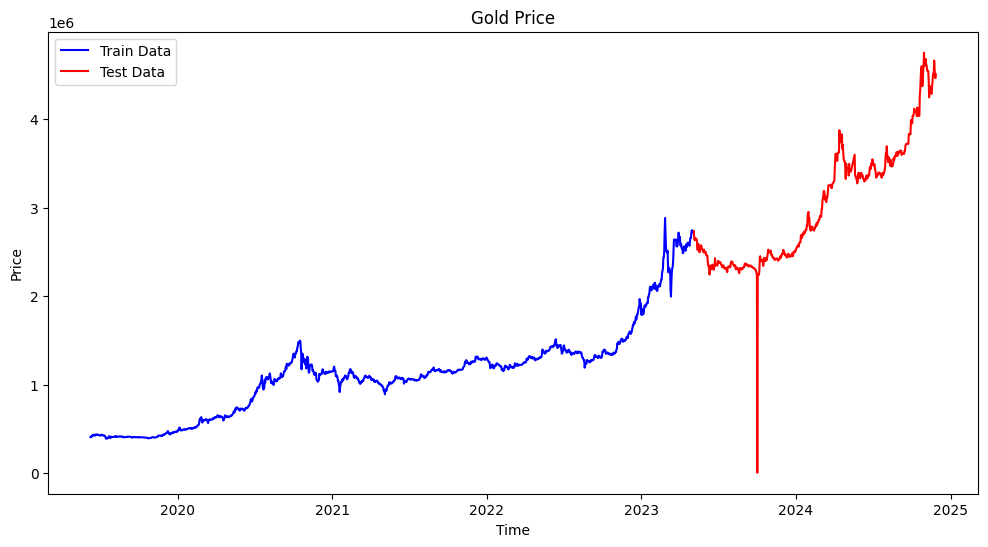

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(train_data['gregorian_date'],
         train_data['close'],
         label='Train Data', color='blue')

plt.plot(test_data['gregorian_date'],
         test_data['close'],
         label='Test Data', color='red')

plt.xlabel('Time')
plt.ylabel('Price')
plt.title('Gold Price')
plt.legend()
plt.show()

In [ ]:
if len(test_data) == 0:
    print("The test data is empty. Please check your data download.")
    test_data_scaled = np.array([])
else:
    scaler = MinMaxScaler()
    train_data_scaled = scaler.fit_transform(train_data[['close']].values)
    test_data_scaled = scaler.transform(test_data[['close']].values)

In [ ]:
lookback = 60  # Number of previous data points to consider
def create_dataset(dataset, look_back=lookback):
    X, Y = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), 0]
        X.append(a)
        Y.append(dataset[i + look_back, 0])
    return np.array(X), np.array(Y)

X_train, y_train = create_dataset(train_data_scaled)
X_test, y_test = create_dataset(test_data_scaled)

X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))


In [ ]:
class LSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(LSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])
        return out

input_dim = 1
hidden_dim = 50
num_layers = 1
output_dim = 1
model = LSTM(input_dim, hidden_dim, num_layers, output_dim)

loss_fn = torch.nn.MSELoss()
optimiser = torch.optim.Adam(model.parameters(), lr=0.01)


In [ ]:
num_epochs = 100
X_train_tensor = torch.from_numpy(X_train).type(torch.Tensor)
y_train_tensor = torch.from_numpy(y_train).type(torch.Tensor)
for t in range(num_epochs):
    y_train_pred = model(X_train_tensor)
    loss = loss_fn(y_train_pred, y_train_tensor.view(-1, 1))
    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

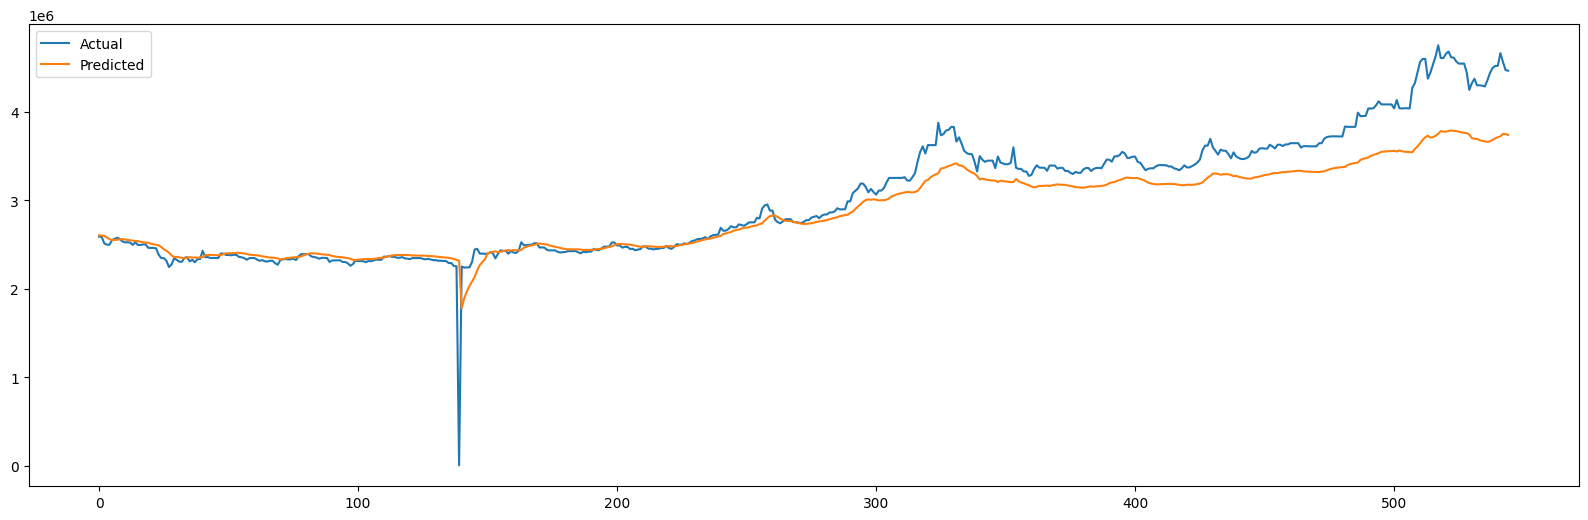

In [ ]:
# 10 days before
X_test_tensor = torch.from_numpy(X_test).type(torch.Tensor)
y_test_pred = model(X_test_tensor)

y_test_pred = scaler.inverse_transform(y_test_pred.detach().numpy())
y_test = scaler.inverse_transform([y_test])
plt.figure(figsize=(20,6))
plt.plot(y_test[0], label='Actual')
plt.plot(y_test_pred, label='Predicted')
plt.legend()
plt.show()

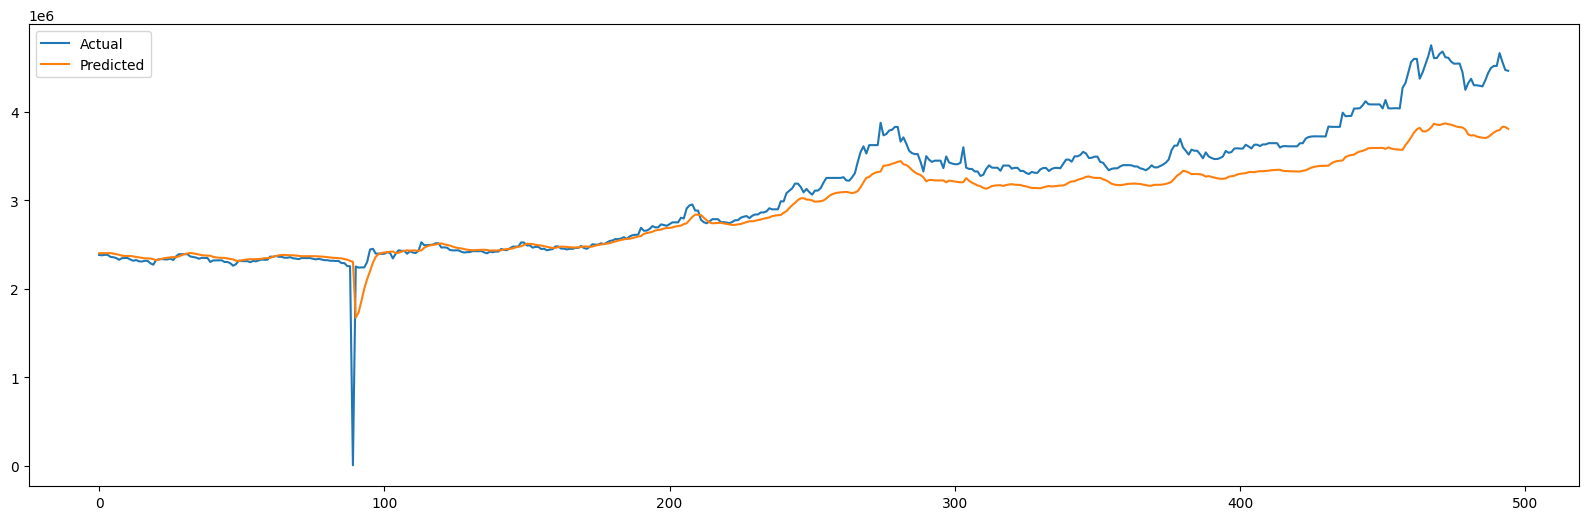

In [ ]:
# 60 days before
X_test_tensor = torch.from_numpy(X_test).type(torch.Tensor)
y_test_pred = model(X_test_tensor)

y_test_pred = scaler.inverse_transform(y_test_pred.detach().numpy())
y_test = scaler.inverse_transform([y_test])
plt.figure(figsize=(20,6))
plt.plot(y_test[0], label='Actual')
plt.plot(y_test_pred, label='Predicted')
plt.legend()
plt.show()

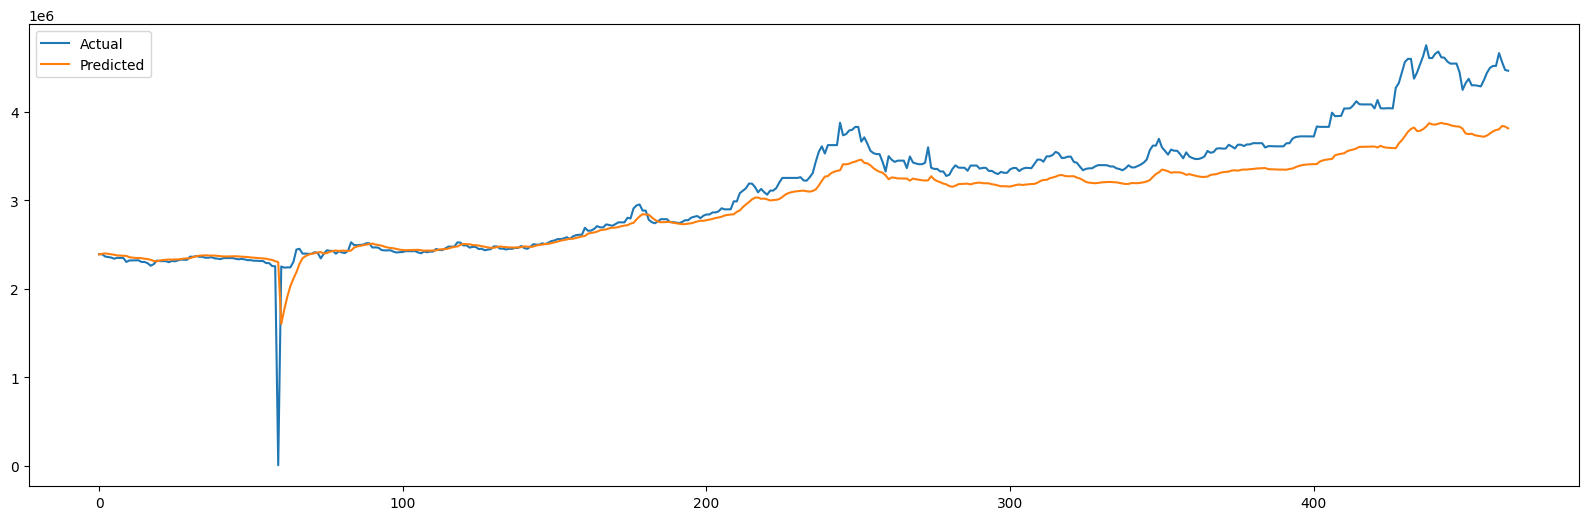

In [ ]:
# 90 days before
X_test_tensor = torch.from_numpy(X_test).type(torch.Tensor)
y_test_pred = model(X_test_tensor)

y_test_pred = scaler.inverse_transform(y_test_pred.detach().numpy())
y_test = scaler.inverse_transform([y_test])
plt.figure(figsize=(20,6))
plt.plot(y_test[0], label='Actual')
plt.plot(y_test_pred, label='Predicted')
plt.legend()
plt.show()

### Market Estimation

In [94]:
!pip install ipywidgets

In [95]:
processing_data = df[df['date'] < '1403-08-13'][['gregorian_date','close']]

In [96]:
processing_data

,gregorian_date,close
0,2019-06-09,410000
1,2019-06-10,415300
2,2019-06-11,411600
3,2019-06-12,414600
4,2019-06-13,428900
...,...,...
1936,2024-10-24,4598550
1937,2024-10-25,4598550
1938,2024-10-26,4375320
1939,2024-10-27,4445030


In [97]:
processing_data['gregorian_date'] = pd.to_datetime(processing_data['gregorian_date'], errors='coerce')
processing_data = processing_data.dropna(subset=['gregorian_date'])
processing_data['close'] = pd.to_numeric(processing_data['close'], errors='coerce')
processing_data = processing_data.dropna(subset=['close'])

In [98]:
processing_data

,gregorian_date,close
0,2019-06-09,410000
1,2019-06-10,415300
2,2019-06-11,411600
3,2019-06-12,414600
4,2019-06-13,428900
...,...,...
1936,2024-10-24,4598550
1937,2024-10-25,4598550
1938,2024-10-26,4375320
1939,2024-10-27,4445030


In [99]:
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets

dates = np.array(processing_data['gregorian_date'])
prices = np.array(processing_data['close'])


plt.figure(figsize=(12, 6))
plt.plot(dates, prices, label='Gold Prices', color='green')
plt.xlabel('Time')
plt.ylabel('Price')
plt.title('Gold Price Plot')

slider = widgets.IntSlider(value=0, min=0, max=len(dates)-1, step=1, description='Select Point:')

def update_plot(index):
    plt.clf()
    plt.plot(dates, prices, label='Gold Prices', color='green')
    plt.scatter(dates[index], prices[index], color='red', zorder=5)
    plt.xlabel('Time')
    plt.ylabel('Price')
    plt.title('Gold Price Plot')
    plt.legend()
    plt.show()


widgets.interactive(update_plot, index=slider)


interactive(children=(IntSlider(value=0, description='Select Point:', max=1940), Output()), _dom_classes=('wid…

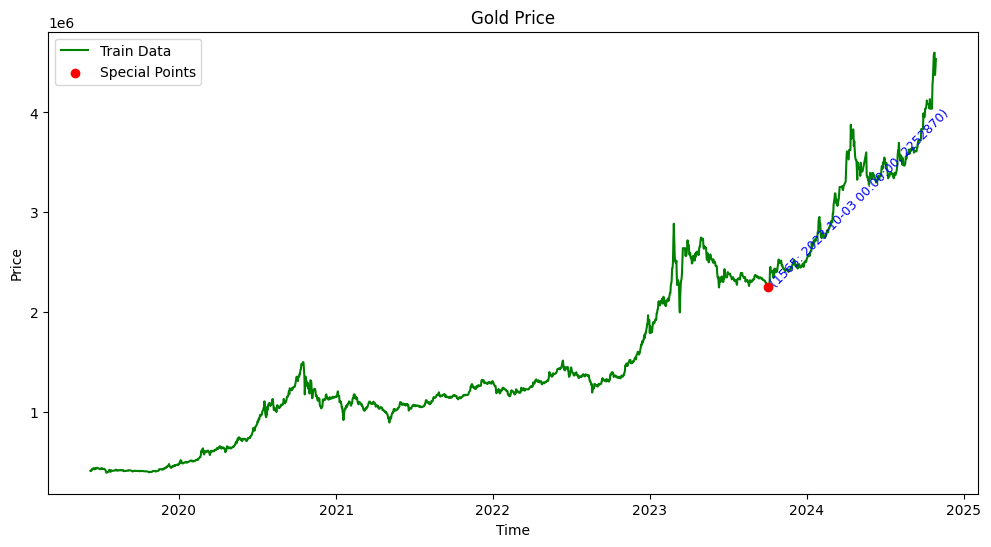

In [100]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

plt.plot(processing_data['gregorian_date'],
         processing_data['close'],
         label='Train Data', color='green')

indexes_to_delete = [1565]
special_dates = processing_data['gregorian_date'].iloc[indexes_to_delete]
special_prices = processing_data['close'].iloc[indexes_to_delete]
plt.scatter(special_dates, special_prices, color='red', label='Special Points', zorder=5)

for idx, date, price in zip(indexes_to_delete, special_dates, special_prices):
    plt.text(date, price, f'({idx}: {date}, {price})', fontsize=9, color='blue', rotation=45)

plt.xlabel('Time')
plt.ylabel('Price')
plt.title('Gold Price')
plt.legend()
plt.show()


In [101]:
processing_data = processing_data.drop(indexes_to_delete, axis=0).reset_index(drop=True)

In [102]:
scaler = MinMaxScaler()
processing_data_scaled = scaler.fit_transform(processing_data[['close']].values)

In [103]:
lookback = 90
def create_dataset(dataset, look_back=lookback):
    X, Y = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), 0]
        X.append(a)
        Y.append(dataset[i + look_back, 0])
    return np.array(X), np.array(Y)


X_final, y_final = create_dataset(processing_data_scaled)
X_final = np.reshape(X_final, (X_final.shape[0], X_final.shape[1], 1))
X_final_tensor = torch.from_numpy(X_final).type(torch.Tensor)
y_final_tensor = torch.from_numpy(y_final).type(torch.Tensor)

In [104]:
class LSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(LSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])
        return out

input_dim = 1
hidden_dim = 50
num_layers = 1
output_dim = 1
model = LSTM(input_dim, hidden_dim, num_layers, output_dim)

loss_fn = torch.nn.MSELoss()
optimiser = torch.optim.Adam(model.parameters(), lr=0.01)


In [105]:
num_epochs = 100
for t in range(num_epochs):
    y_final_pred = model(X_final_tensor)
    loss = loss_fn(y_final_pred, y_final_tensor.view(-1, 1))
    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

In [106]:
last_sequence = processing_data_scaled[-lookback:].reshape(1, lookback, 1)
predictions = []

for _ in range(30):
    last_sequence_tensor = torch.from_numpy(last_sequence).type(torch.Tensor)
    next_day_pred = model(last_sequence_tensor).detach().numpy()
    predictions.append(next_day_pred[0, 0])  # Collect the prediction
    # Update the last sequence with the new prediction
    last_sequence = np.append(last_sequence[:, 1:, :], next_day_pred.reshape(1, 1, 1), axis=1)

# Transform predictions back to original scale
predicted_prices = scaler.inverse_transform(np.array(predictions).reshape(-1, 1))


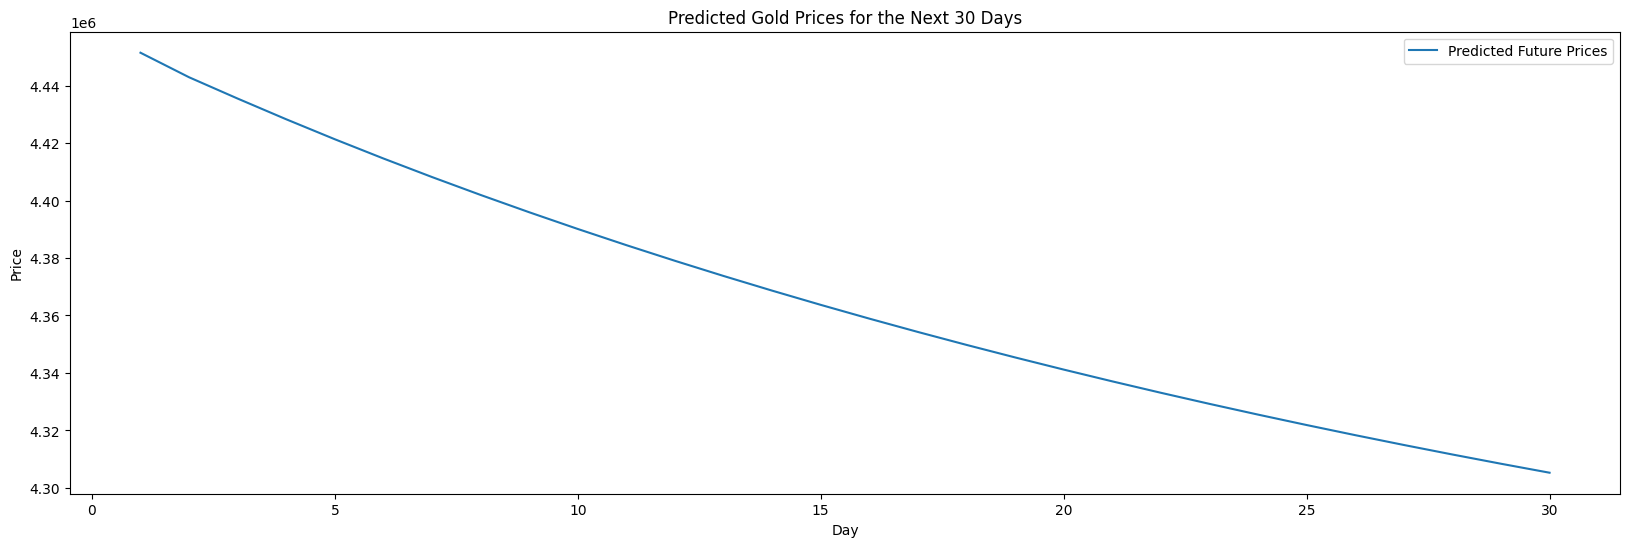

In [107]:
plt.figure(figsize=(20, 6))
plt.plot(range(1, 31), predicted_prices, label='Predicted Future Prices')
plt.title("Predicted Gold Prices for the Next 30 Days")
plt.xlabel("Day")
plt.ylabel("Price")
plt.legend()
plt.show()